# Why DyNeMo with learned means overfits, and how coordinated dropout fixes it

This notebook explains a problem we found when DyNeMo learns **mode means**
(`learn_means=True`), shows it happening in a 3-channel toy simulation, and shows how a
small training change, **coordinated dropout**, fixes it.

Everything here uses simulated data with a known ground truth. It needs a version of
osl-dynamics with the `coordinated_dropout` option for DyNeMo (branch
`dynemo-coordinated-dropout`). Running the whole notebook takes about 15 minutes on 4 CPUs
(two short trainings).

**In one paragraph.** With means on, DyNeMo's mode time course $\alpha_t$ can follow the data's
own moment-to-moment wiggles, including noise that belongs to individual channels. The
covariance is then learned from what is left after that, which is almost nothing in those
directions, so the model claims a precision it does not have. On held-out channels (which is
what bi-cross-validation tests), that noise comes back and the model is heavily penalised.
Coordinated dropout fixes this by never letting $\alpha$ see the channels it is being scored on
during training. Nothing changes when the trained model is used.

## 1. What DyNeMo assumes (a 30-second recap)

At each time point $t$, the data $x_t$ (one number per channel) is modelled as a Gaussian:

$$x_t \sim \mathcal{N}(m_t, C_t), \qquad m_t = \sum_k \alpha_{tk}\,\mu_k, \qquad C_t = \sum_k \alpha_{tk}\,D_k .$$

- $\mu_k$ and $D_k$ are each mode's mean and covariance. They are learned once and shared across time.
- $\alpha_t$ says how much of each mode is "on" at time $t$ (non-negative, sums to 1).
- $\alpha_t$ is computed by an **encoder** (the inference RNN) that reads the data forwards and
  backwards in time, **including $x_t$ itself**.
- A **prior** (the model RNN) predicts how $\alpha$ should move. Training pays a cost (the KL
  term) when $\alpha$ does something the prior did not expect.

## 2. The problem, in plain words

Think of training as an exam. At every time point the model is marked on how well $m_t$ and
$C_t$ explain $x_t$, and $\alpha_t$ is its answer.

1. **The exam is open-book.** The encoder sees $x_t$ before it chooses $\alpha_t$.
2. **With means on, $\alpha$ controls a dial.** $m_t$ moves smoothly with $\alpha_t$, so $\alpha$ can turn the
   dial to wherever $x_t$ actually is, *including the part of $x_t$ that is just noise in that
   particular channel* ("private noise"). The encoder can't tell signal from noise; matching the
   data exactly always scores best.
3. **The covariance learns from what's left over.** $C_t$ is fitted to $x_t - m_t$. If $m_t$ has
   already absorbed the noise in some direction, nothing is left there, and $C_t$ claims (almost)
   zero variance in that direction.
4. **Nothing stops it.** The only brake is the KL cost. fMRI noise is slow and smooth, so the prior
   can predict a smoothly wiggling $\alpha$ easily and following the noise costs very little.

**Why it only happens with means on.** Without means, $\alpha$ only changes the *spread* $C_t$, never
the predicted value, so it can't follow $x_t$. In an HMM, $\alpha$ is (almost) 0 or 1 and sticky, so
$m_t$ can only take a few fixed values.

**Why it matters.** When $\alpha$ has to be worked out *without* seeing some channels (as in
bi-cross-validation), it can't follow their private noise any more. The noise comes back, but the
model has said it can't be there, so every miss is penalised as if it were almost impossible.

## 3. A toy simulation with 3 channels

Every channel is the same shared signal plus its own private noise:

$$x_{c,t} = f_t + n_{c,t}, \qquad c = 1, 2, 3 .$$

- $f_t$ is shared by all channels. It comes from 2 soft modes with means $(+a,+a,+a)$ and
  $(-a,-a,-a)$, so $f_t = a\,(2\alpha_{t1} - 1)$.
- $n_{c,t}$ is private noise, independent across channels and slow (AR(1) with coefficient 0.9, like fMRI).
- $\mathrm{Var}(f) = \mathrm{Var}(n_c) = 0.5$, so each channel has unit variance and every pair of
  channels correlates at $r = 0.5$.

**What a correct model should learn:** $m_t \approx f_t\,(1,1,1)$, and a leftover covariance of
$0.5\,I$ (independent private noise, no correlation between channels).

We use 3 channels because it's the smallest number where the fix can also learn the covariance
*between* channels (hide two, show one).

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import logging
import tempfile

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from osl_dynamics.data import Data
from osl_dynamics.models.dynemo import Config, Model
from osl_dynamics.inference.layers import CoordinatedDropoutLayer

logging.getLogger("osl-dynamics").setLevel(logging.WARNING)
print("TensorFlow", tf.__version__)

# Colours: no dropout = orange, coordinated dropout = blue, truth = black dashed, data = grey
OLD, NEW, TRUTH, DATA = "#eb6834", "#2a78d6", "#0b0b0b", "#9a9893"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
                     "lines.linewidth": 2, "figure.dpi": 110})

N_CHANNELS = 3
PRIVATE_VAR = 0.5   # variance of each channel's private noise
SHARED_VAR = 0.5    # variance of the shared signal f
N_EPOCHS = 50

TensorFlow 2.19.1


data shape (sessions, time points, channels): (200, 1200, 3)
variance of each channel: [1. 1. 1.]
correlation between channels:
 [[1.  0.5 0.5]
 [0.5 1.  0.5]
 [0.5 0.5 1. ]]
lag-1 autocorrelation of the private noise: 0.9


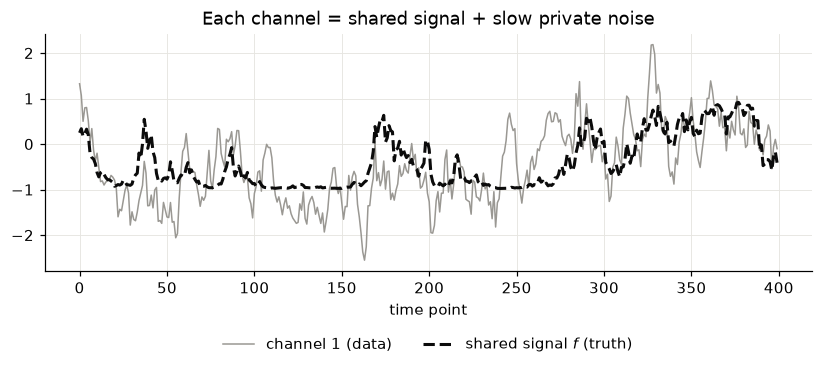

In [2]:
def simulate(n_channels=N_CHANNELS, n_sessions=200, n_samples=1200, phi=0.9, seed=0):
    # x_c = f + n_c, with f driven by 2 soft modes and n_c slow private AR(1) noise
    rng = np.random.default_rng(seed)

    def ar1(n, k, coef, std):
        out = np.empty((n, k))
        out[0] = rng.normal(0, std, k)
        innov = std * np.sqrt(1 - coef ** 2)
        for t in range(1, n):
            out[t] = coef * out[t - 1] + rng.normal(0, innov, k)
        return out

    alpha, f, e = [], [], []
    for _ in range(n_sessions):
        theta = ar1(n_samples, 2, 0.98, 1.0)          # slow mode logits
        a = np.exp(2 * theta)
        a /= a.sum(1, keepdims=True)                  # alpha: soft mixture of 2 modes
        alpha.append(a)
        f.append(2 * a[:, 0] - 1)                     # shared signal (before scaling)
        e.append(ar1(n_samples, n_channels, phi, np.sqrt(PRIVATE_VAR)))
    alpha, f, e = np.array(alpha), np.array(f), np.array(e)
    f = f * np.sqrt(SHARED_VAR / f.var())
    x = f[..., None] + e
    return x.astype(np.float32), alpha, f, e


x, alpha_true, f, e = simulate()
x_flat = x.reshape(-1, N_CHANNELS)
print("data shape (sessions, time points, channels):", x.shape)
print("variance of each channel:", x_flat.var(0).round(2))
print("correlation between channels:\n", np.corrcoef(x_flat.T).round(2))
print("lag-1 autocorrelation of the private noise:",
      round(np.corrcoef(e[0, :-1, 0], e[0, 1:, 0])[0, 1], 2))

window = slice(0, 400)
fig, ax = plt.subplots(figsize=(9, 2.8))
ax.plot(x[0, window, 0], color=DATA, lw=1, label="channel 1 (data)")
ax.plot(f[0, window], color=TRUTH, ls="--", label="shared signal $f$ (truth)")
ax.set_xlabel("time point"); ax.set_title("Each channel = shared signal + slow private noise")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2, frameon=False)
plt.show()

## 4. Current behaviour: DyNeMo with means, no dropout

We train DyNeMo with 2 modes and `learn_means=True` with the default
`coordinated_dropout=0`, i.e. exactly as DyNeMo works today.

In [3]:
def train_dynemo(data, coordinated_dropout, n_epochs=N_EPOCHS, seed=0):
    tf.random.set_seed(seed)
    np.random.seed(seed)
    config = Config(
        n_modes=2, n_channels=N_CHANNELS, sequence_length=100,
        inference_n_units=64, inference_normalization="layer",
        model_n_units=64, model_normalization="layer",
        learn_alpha_temperature=True, initial_alpha_temperature=1.0,
        learn_means=True, learn_covariances=True,
        do_kl_annealing=True, kl_annealing_curve="tanh", kl_annealing_sharpness=5,
        n_kl_annealing_epochs=n_epochs // 2,
        batch_size=32, learning_rate=1e-3, n_epochs=n_epochs,
        n_init=5, n_init_epochs=2,
        coordinated_dropout=coordinated_dropout,   # 0 = current behaviour
    )
    model = Model(config)
    model.set_regularizers(data)
    model.train(data, verbose=0)                   # initialisation + full training
    return model


data = Data(list(x), store_dir=tempfile.mkdtemp())
old_model = train_dynemo(data, coordinated_dropout=0)

Loading files:   0%|          | 0/200 [00:00<?, ?it/s]

 1/75 ━━━━━━━━━━━━━━━━━━━━ 48s 660ms/step

 4/75 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step  

 7/75 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step

10/75 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step

...

64/75 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step

67/75 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step

70/75 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step

73/75 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step

75/75 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step


We look at three things:

1. **What does the model's mean follow?** We regress the model's mean (averaged over channels) on
   the true shared signal and on the true private noise (averaged over channels). An honest model
   gives coefficients (1, 0): it follows the shared signal and ignores the noise.
2. **What leftover covariance does it claim?** The truth is $0.5\,I$.
3. **How much noise does it claim for the average of the three channels?** That is the direction
   in which the mean can move. The truth is 0.5.

In [4]:
U_AVG = np.ones(N_CHANNELS) / np.sqrt(N_CHANNELS)   # the "average of all channels" direction


def diagnose(model):
    # remove_edge_effects: infer on 50%-overlapping sequences so there are no jumps at sequence boundaries
    alpha = np.concatenate(model.get_alpha(data, remove_edge_effects=True))   # (time, modes)
    means, covs = model.get_means_covariances()
    m = alpha @ means                                       # model's predicted mean at each time point
    C_t = np.einsum("tk,kij->tij", alpha, covs)              # model's leftover covariance at each time point
    C = C_t.mean(0)                                          # ... averaged over time
    f_flat, e_flat = f.reshape(-1), e.reshape(-1, N_CHANNELS)

    X = np.column_stack([f_flat, e_flat.mean(1), np.ones(len(f_flat))])
    b_shared, b_private = np.linalg.lstsq(X, m.mean(1), rcond=None)[0][:2]

    # KL(truth || model) per time point: how far the model's belief is from the true distribution
    # N(f_t * 1, 0.5 I). 0 means perfect.
    idx = np.random.default_rng(0).choice(len(m), 5000, replace=False)
    C_true = PRIVATE_VAR * np.eye(N_CHANNELS)
    d = m[idx] - f_flat[idx, None]
    Cinv = np.linalg.inv(C_t[idx])
    kl = 0.5 * (np.einsum("tij,ji->t", Cinv, C_true) + np.einsum("ti,tij,tj->t", d, Cinv, d)
                - N_CHANNELS + np.linalg.slogdet(C_t[idx])[1] - np.linalg.slogdet(C_true)[1])
    return dict(m=m, C=C, b_shared=b_shared, b_private=b_private,
                claimed_avg=U_AVG @ C @ U_AVG, kl=kl.mean())


def report(name, d):
    print(f"{name}")
    print(f"  model mean = {d['b_shared']:.2f} x shared signal + {d['b_private']:.2f} x private noise   (honest: 1, 0)")
    print(f"  leftover covariance (truth = 0.5 on the diagonal, 0 elsewhere):\n{np.round(d['C'], 2)}")
    print(f"  claimed noise variance for the channel average: {d['claimed_avg']:.3f}   (truth = {PRIVATE_VAR})")
    print(f"  KL(truth || model) per time point: {d['kl']:.2f}   (0 = perfect)")


old = diagnose(old_model)
report("NO DROPOUT (default)", old)

Getting alpha:   0%|          | 0/200 [00:00<?, ?it/s]

NO DROPOUT (default)
  model mean = 0.99 x shared signal + 0.94 x private noise   (honest: 1, 0)
  leftover covariance (truth = 0.5 on the diagonal, 0 elsewhere):
[[ 0.34 -0.17 -0.14]
 [-0.17  0.33 -0.14]
 [-0.14 -0.14  0.37]]
  claimed noise variance for the channel average: 0.044   (truth = 0.5)
  KL(truth || model) per time point: 9.54   (0 = perfect)


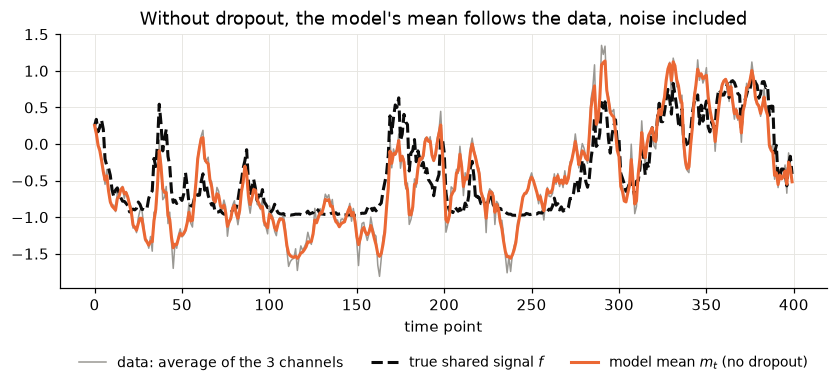

In [5]:
f_flat = f.reshape(-1)
window = slice(0, 400)
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(x_flat[window].mean(1), color=DATA, lw=1, label="data: average of the 3 channels")
ax.plot(f_flat[window], color=TRUTH, ls="--", label="true shared signal $f$")
ax.plot(old["m"][window].mean(1), color=OLD, label="model mean $m_t$ (no dropout)")
ax.set_xlabel("time point")
ax.set_title("Without dropout, the model's mean follows the data, noise included")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=3, frameon=False, fontsize=9)
plt.show()

**What we see.**

- **The mean copies the noise.** The orange line sits on top of the grey data, not on the black
  dashed shared signal. Its private-noise coefficient is close to 1.
- **The covariance has been squeezed.** Its off-diagonal values are negative even though the true
  leftover noise is uncorrelated. That's the signature of "the mean already took out the channel
  average".
- **It's badly overconfident about the channel average.** It claims a tiny noise variance there,
  when the truth is 0.5.

Training was happy with this because, in-sample, the copying works: the leftover really is tiny in
that direction.

### Why this breaks on held-out channels

Suppose $\alpha$ is worked out *without* seeing these channels, as in bi-cross-validation, where
$\alpha$ comes from other channels. Then it can know the shared signal at best, never the private
noise. So the true leftover along the channel average is the private noise, with variance 0.5. The
model claimed much less.

For a Gaussian with variance claimed as $v_\text{claimed}$ when the truth is $v_\text{true}$, the
log-likelihood lost per time point is $\tfrac12\,(r - 1 - \ln r)$ with $r = v_\text{true}/v_\text{claimed}$.

In [6]:
def penalty(v_true, v_claimed):
    r = v_true / v_claimed
    return 0.5 * (r - 1 - np.log(r))


print(f"no dropout: claims {old['claimed_avg']:.3f}, truth {PRIVATE_VAR}: "
      f"{PRIVATE_VAR / old['claimed_avg']:.0f}x too confident, "
      f"loses {penalty(PRIVATE_VAR, old['claimed_avg']):.1f} nats per time point in that one direction")

no dropout: claims 0.044, truth 0.5: 11x too confident, loses 3.9 nats per time point in that one direction


That is the toy version of what happened on HCP. There, the same mechanism made DyNeMo's
bi-cross-validated log-likelihood worse than the static (one-state) model for every number of modes.

## 5. The fix: coordinated dropout

**Idea: make the exam closed-book.** For each training sequence, randomly **hide some channels**
from the encoder, and **mark the model only on the hidden channels**.

In the toy: hide $x_2$ and $x_3$, so $\alpha$ only sees $x_1 = f + n_1$.
- $\alpha$ can learn about $f$, because $f$ is also in $x_2$ and $x_3$.
- $\alpha$ can never learn $n_2$ or $n_3$; it hasn't seen them.
- So the miss on the hidden channels is (at least) their private noise, and $C_t$ is forced to learn its real size.
- Copying no longer pays, because you can't copy what you can't see.

Two details matter.
- **Hide whole channels for the whole sequence.** Hiding $x_2$ only at time $t$ is not enough: the
  signals are slow, so the encoder could fill $x_2(t)$ in from $x_2(t-1)$ and $x_2(t+1)$.
- **Only during training.** When you use the trained model (`get_alpha`, free energy, BCV),
  nothing is hidden and every channel is used, exactly as before.

### What changed in the code

| piece | where | what it does |
|---|---|---|
| `CoordinatedDropoutLayer` | `osl_dynamics/inference/layers.py` | For each sequence, hides each channel with probability `rate` (at least one hidden, one visible). Zeroes the hidden channels in the encoder's input and returns a mask. Does nothing outside training. |
| `LogLikelihoodLossLayer` (optional mask) | `osl_dynamics/inference/layers.py` | With a mask, the log-likelihood is that of the hidden channels only (their Gaussian marginal), rescaled by `n_channels / n_hidden` so it stays on the usual scale. |
| `coordinated_dropout` | `dynemo.Config` | The rate. Default 0, which is the current behaviour. |

With 3 channels, the "at least one hidden, at least one visible" rule means each sequence hides 1
or 2 channels.

In [7]:
# What the layer does to a batch of 6 sequences (4 time points, 3 channels, all ones)
layer = CoordinatedDropoutLayer(rate=0.5)
batch = tf.ones((6, 4, N_CHANNELS))

encoder_input, mask = layer(batch, training=True)
print("TRAINING: mask per sequence (1 = hidden from the encoder and scored in the loss)")
print(mask.numpy()[:, 0, :].astype(int))
print("encoder input for sequence 0, first time point (hidden channels zeroed, others rescaled):",
      encoder_input.numpy()[0, 0])

encoder_input, mask = layer(batch, training=False)
print("\nUSING THE TRAINED MODEL: nothing hidden ->", "input unchanged:",
      bool(np.all(encoder_input.numpy() == 1)), "| mask selects every channel:",
      bool(np.all(mask.numpy() == 1)))

TRAINING: mask per sequence (1 = hidden from the encoder and scored in the loss)
[[1 0 1]
 [0 1 1]
 [0 1 0]
 [0 1 0]
 [0 1 1]
 [0 1 0]]
encoder input for sequence 0, first time point (hidden channels zeroed, others rescaled): [0. 2. 0.]

USING THE TRAINED MODEL: nothing hidden -> input unchanged: True | mask selects every channel: True


## 6. Train with coordinated dropout and compare

Same data, same settings, only `coordinated_dropout=0.5`.

In [8]:
new_model = train_dynemo(data, coordinated_dropout=0.5)
new = diagnose(new_model)
report("NO DROPOUT (default)", old)
print()
report("WITH COORDINATED DROPOUT", new)
print()
for name, d in [("no dropout", old), ("coordinated dropout", new)]:
    print(f"{name}: claims {d['claimed_avg']:.3f} for the channel average (truth {PRIVATE_VAR}), "
          f"held-out penalty {penalty(PRIVATE_VAR, d['claimed_avg']):.2f} nats per time point")

 1/75 ━━━━━━━━━━━━━━━━━━━━ 46s 622ms/step

 4/75 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step  

 7/75 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step

10/75 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step

13/75 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step

...

70/75 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step

73/75 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step

75/75 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step


Getting alpha:   0%|          | 0/200 [00:00<?, ?it/s]

NO DROPOUT (default)
  model mean = 0.99 x shared signal + 0.94 x private noise   (honest: 1, 0)
  leftover covariance (truth = 0.5 on the diagonal, 0 elsewhere):
[[ 0.34 -0.17 -0.14]
 [-0.17  0.33 -0.14]
 [-0.14 -0.14  0.37]]
  claimed noise variance for the channel average: 0.044   (truth = 0.5)
  KL(truth || model) per time point: 9.54   (0 = perfect)

WITH COORDINATED DROPOUT
  model mean = 0.69 x shared signal + 0.24 x private noise   (honest: 1, 0)
  leftover covariance (truth = 0.5 on the diagonal, 0 elsewhere):
[[0.69 0.2  0.21]
 [0.2  0.69 0.21]
 [0.21 0.21 0.68]]
  claimed noise variance for the channel average: 1.095   (truth = 0.5)
  KL(truth || model) per time point: 0.30   (0 = perfect)

no dropout: claims 0.044 for the channel average (truth 0.5), held-out penalty 3.92 nats per time point
coordinated dropout: claims 1.095 for the channel average (truth 0.5), held-out penalty 0.12 nats per time point


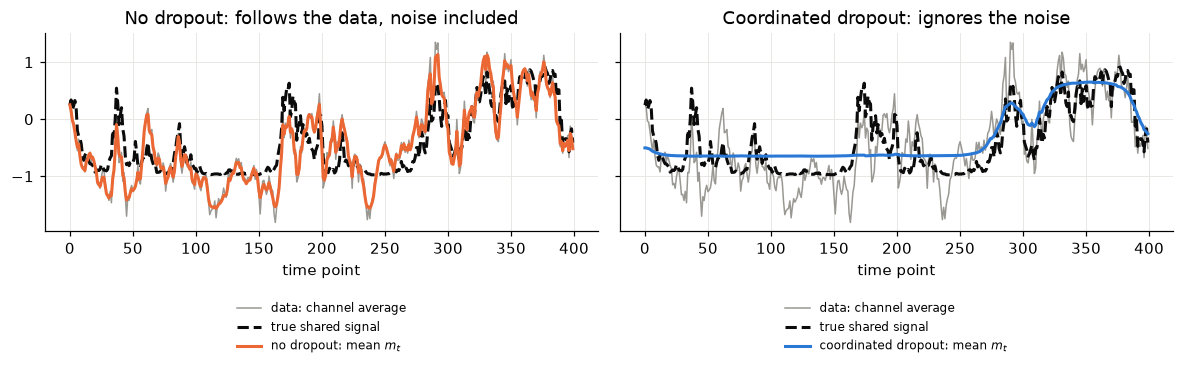

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, (name, d, colour) in zip(axes, [("no dropout", old, OLD),
                                        ("coordinated dropout", new, NEW)]):
    ax.plot(x_flat[window].mean(1), color=DATA, lw=1, label="data: channel average")
    ax.plot(f_flat[window], color=TRUTH, ls="--", label="true shared signal")
    ax.plot(d["m"][window].mean(1), color=colour, label=f"{name}: mean $m_t$")
    ax.set_xlabel("time point")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=1, frameon=False, fontsize=8)
axes[0].set_title("No dropout: follows the data, noise included")
axes[1].set_title("Coordinated dropout: ignores the noise")
plt.tight_layout()
plt.show()

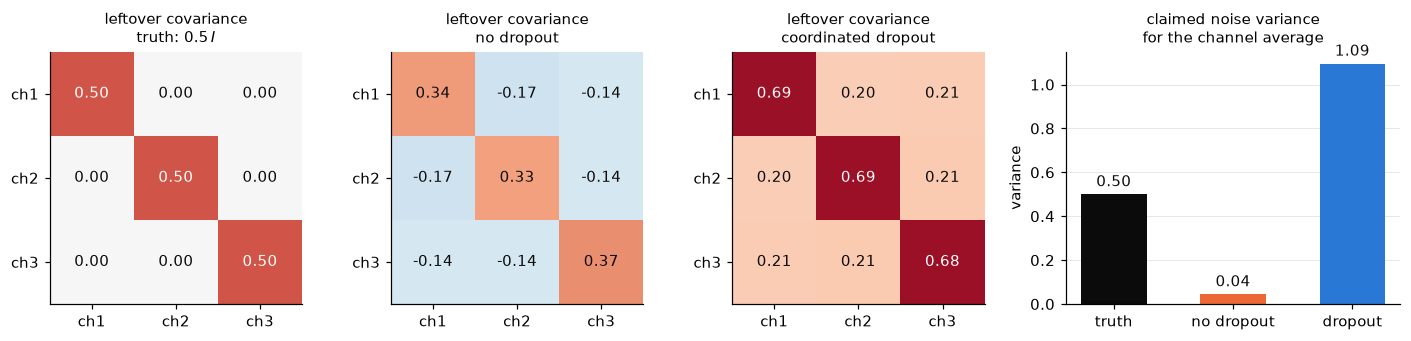

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2), gridspec_kw={"width_ratios": [1, 1, 1, 1.25]})
panels = [("truth: $0.5\\,I$", PRIVATE_VAR * np.eye(N_CHANNELS)),
          ("no dropout", old["C"]), ("coordinated dropout", new["C"])]
for ax, (title, C) in zip(axes[:3], panels):
    ax.imshow(C, cmap="RdBu_r", vmin=-0.8, vmax=0.8)
    for i in range(N_CHANNELS):
        for j in range(N_CHANNELS):
            ax.text(j, i, f"{C[i, j]:.2f}", ha="center", va="center", fontsize=10,
                    color="white" if abs(C[i, j]) > 0.45 else "#0b0b0b")
    ax.set_xticks(range(N_CHANNELS), [f"ch{c + 1}" for c in range(N_CHANNELS)])
    ax.set_yticks(range(N_CHANNELS), [f"ch{c + 1}" for c in range(N_CHANNELS)])
    ax.grid(False)
    ax.set_title(f"leftover covariance\n{title}", fontsize=10)

ax = axes[3]
names, values, colours = ["truth", "no dropout", "dropout"], [PRIVATE_VAR, old["claimed_avg"], new["claimed_avg"]], [TRUTH, OLD, NEW]
ax.bar(names, values, color=colours, width=0.55)
ax.grid(axis="x", visible=False)
ax.set_axisbelow(True)
for i, v in enumerate(values):
    ax.text(i, v + 0.02, f"{v:.2f}", ha="center", va="bottom", fontsize=10, color="#0b0b0b")
ax.set_ylabel("variance")
ax.set_title("claimed noise variance\nfor the channel average", fontsize=10)
plt.tight_layout()
plt.show()

## 7. Why it fixed the problem

- **Without dropout**, the model was marked on channels it had just looked at, so the best strategy was to copy
  them, noise included. The covariance then claimed almost no noise in the direction the mean could
  move. It was far too confident, which is very expensive on held-out channels.
- **With coordinated dropout**, the model is only ever marked on channels the encoder did not see. Whatever $\alpha$ knows
  has to come from *other* channels, which share $f$ but not each other's private noise. So
  $\alpha$ learns the shared signal, and the covariance learns how much is left over *when you can't
  see the channel*. Nothing collapses, and the mean no longer copies the noise.

**Why the model with dropout is a bit too cautious here.** With only 3 channels, $\alpha$ sees just 1 or 2 of
them during training, so it recovers $f$ only partly ($m_t$ follows about 0.7 of $f$). The covariance
honestly reports the extra uncertainty: it's larger than 0.5, with small positive correlations,
which is the part of $f$ that $\alpha$ couldn't pin down. That is the safe direction. Being about 2x too
cautious costs around 0.1 nats per time point; being 10-20x too confident costs several nats. With
more channels, $f$ is recovered much better and the gap closes: in a 20-channel simulation, no direction
of the model's covariance under-claimed the true noise by more than about 5% (smallest eigenvalue
relative to the truth about 0.95, against 0.13 without dropout).

## 8. Summary (for the osl-dynamics maintainers)

**Problem.** With `learn_means=True`, DyNeMo's encoder sees $x_t$, and $m_t$ is linear in $\alpha_t$. So $\alpha$
can follow channel-specific (private) fluctuations, and the covariance collapses along those
directions. This is cheap when the private noise is slow (as in fMRI). It doesn't show in mode maps,
only in likelihood-based checks such as bi-cross-validation. HMM and DyNeMo without means are not
affected.

**Fix.** Coordinated dropout in training (Keshtkaran & Pandarinath, NeurIPS 2019; the same failure
was seen in LFADS). For each sequence, whole channels are hidden from the encoder, and the
log-likelihood is computed only on those hidden channels (their marginal Gaussian). It's enabled with
`dynemo.Config(coordinated_dropout=0.25)`. The default of 0 keeps the current behaviour.

**Evidence from a larger simulation study** (run with the research version of this change;
20 channels, 4 modes, known truth, slow private noise):

| model (K=4, 100 epochs) | KL to truth (static model 2.6, oracle 0) | smallest covariance eigenvalue vs truth |
|---|---|---|
| DyNeMo + means (no dropout) | 11.8-12.4 | 0.13-0.15 |
| DyNeMo + means + coordinated dropout 0.25 | 0.68-0.69 | 0.94-0.95 |

- The same holds at K = 2 and 8, and at HCP scale (500 x 4800 samples, 25 channels) with the
  ICA_50_mean training config: 15-16 without dropout against 0.71 with it.
- The cost when there is nothing to fix (white private noise) is about 0.05 nats per time point.

**Notes.**
- Training-only: inference, free energy and BCV evaluation are unchanged.
- Free energies of models trained with and without dropout are not comparable.
- A rate of 0.5 sometimes gave a dead mode unless more initialisations were used; 0.1-0.25 worked
  in every run.
- This is different from the existing `inference_dropout`, which drops individual values and still
  scores every channel. That leaves the copying in place: slow signals let the encoder fill in a
  dropped value from its neighbours, and the copied channels are still scored.
- Only DyNeMo has the option so far. M-DyNeMo has the same encoder and mean structure, and showed
  the same problem in simulations; the same two-line change fixed it there.
- Real-data checks (HCP bi-cross-validation) are in progress.